In [1]:
import h5py
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from datetime import datetime
import matplotlib.cm as cm
import numpy as np
import xarray as xr
import seaborn as sns
import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils
from datetime import datetime, timezone

from scipy.signal import find_peaks

from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

from MPG_HDF5_libs import *

In [2]:
# import the data
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

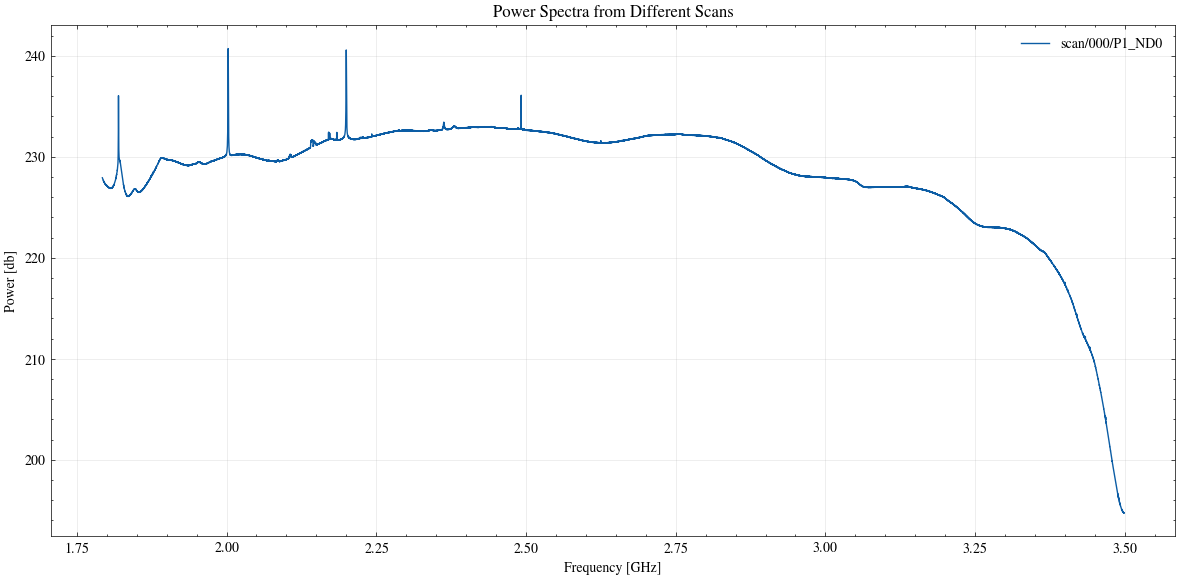

In [3]:
# Select different group os data

groups = [
    "scan/000/P1_ND0",
    # "scan/000/P1_ND1",
    # "scan/001/P0_ND0",
    # "scan/001/P0_ND1",
    # "scan/001/P1_ND0",
    # "scan/001/P1_ND1"
]



# plot the power spectrum
with h5py.File(filename,'r') as f:
    for g in groups:
        spectrum = f[f"{g}/spectrum"][:,1600:-60]
        # Average convert the power spectrum to dB
        spectrum_dB = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

        # define the varibles
        time = f['scan/000/P0_ND0/timestamp'][:,0]  # shape  (666,)
        freq = f[f"{g}/frequency"][1600:-60] / 1e9   # convert Hz -> GHz shape (65537,)



        # Plot
        plt.figure(figsize=(12,6))
        plt.plot(freq, spectrum_dB, label=g)

        plt.xlabel("Frequency [GHz]")
        plt.ylabel("Power [db]")
        plt.title("Power Spectra from Different Scans")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()


### The functions

In [4]:
# Baseline correction

def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method:Asymmetric Least Square

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    the signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline





##############################################
#                                            #
#                                            #
#                                            #
#                                            #
##############################################





# Define a function to quantify the RFI width
def quantify_RFI_width(freq, power, ax=None):
    """
    Quantify how wide an RFI peak is in frequency.

    Parameters:
    freq : array
        Frequency array.
    power : array
        Power array with baseline corrected.
    mask : boolean array
        Mask to select the frequency window of interest.

    Returns:
    start_freq : float
        Frequency where power rises above threshold.
    end_freq : float
        Frequency where power falls below threshold.
    peak_freq : float
        Frequency of the peak power.
    peak_power : float
        Value of the peak power.
    """


    # --- 1) Find where power rises above zero ---
    threshold = 0.05  # small threshold 
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) > 0:
        start_index = above_threshold[0]
        end_index = above_threshold[-1]
        start_freq = freq[start_index]
        end_freq = freq[end_index]
    else:
        start_freq = end_freq = np.nan
        print("No significant power detected in the masked range.")

    # --- 2) Find the frequency of the peak ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]


    print(f"=== Start Frequency: {start_freq:.4f} GHz ===")
    print(f"=== End Frequency: {end_freq:.4f} GHz ===")
    print(f"=== Peak Frequency: {peak_freq:.4f} GHz with Power: {peak_power:.4f} dB ===")
    


    # Number of channels corrupted.
    delta_frequency = (freq[1] - freq[0])  # spectral resolution / channel width
    chans = ((end_freq - start_freq) / delta_frequency)


    print(f'=== Number off corrupted channels: {chans: .1f} ===')
    print(f'=== Bandwidth of corrupeted frequency: {(end_freq-start_freq)*1e3:.1f} MHz ===')



    # --- Plot results ---

    if ax is None:
        fig,ax = plt.subplots(figsize=(12,6))

    ax.plot(freq, power, '.', color='steelblue', label='Data')
    ax.axvline(start_freq, color='green', linestyle='--', label='Start')
    ax.axvline(peak_freq, color='red', linestyle='-', label='Peak')
    ax.axvline(end_freq, color='orange', linestyle='--', label='End')
    ax.set_xlabel('Frequency [GHz]', fontsize=16)
    ax.set_ylabel('Power [dB]', fontsize=16)
    ax.legend(fontsize=14)
    ax.grid(linestyle='--')

    return start_freq, end_freq, peak_freq, peak_power







##############################################
#                                            #
#                                            #
#                                            #
#                                            #
##############################################





# Waterfall plot function for specified frequency range
def waterfall_timevsfreq(time, freq, spectrum, freq_mask, ax=None):
    """
    Generate a waterfall plot of power vs time and frequency.

    Parameters:
    time : array
        Time array in seconds since epoch.
    freq : array
        Frequency array in GHz.
    spectrum : 2D array
        Power spectrum with shape (time, frequency).
    freq_mask : boolean array
        Mask to select the frequency range of interest.
   ax : matplotlib.axes.Axes, optional
        Axis on which to draw the plot. If None, creates a new one.

    Returns:
    ax : matplotlib.axes.Axes
        The axis with the plotted data.
    """

    # --- Convert Power Spectrum to dB ---
    spectrum_db = 10 * np.log10(spectrum**2 + 1e-12)

    # Select the desired frequency channels
    power_channel = spectrum_db[:, freq_mask]

    # --- Convert Time to UTC Datetime ---
    time_utc = pd.to_datetime(time, unit="s", utc=True)

    # --- Select Frequency Range (GHz) ---
    freq_sel = freq[freq_mask]

    # --- Plot Waterfall (Frequency on x, Time on y) ---

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # --- Create Waterfall ---
    im = ax.imshow(
        power_channel,
        aspect='auto',
        origin='lower',
        extent=[freq_sel.min(), freq_sel.max(), 0, len(time_utc)],
        cmap='viridis'
    )

    # --- Colorbar ---

    cbar = plt.colorbar(im, ax=ax, label='Power [dB]')
    cbar.ax.tick_params(labelsize=14)       # set tick label size
    cbar.set_label('Power [dB]', fontsize=16)  # set label font size
    
    ax.set_xlabel('Frequency [GHz]', fontsize=16)
    ax.set_ylabel('Time [UTC]', fontsize=16)
    #plt.title('Waterfall Plot: Time vs Frequency', fontsize=18)

    # --- Y-axis: Time Ticks (UTC) ---
    n_ticks = 10
    tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]
    ax.set_yticks(tick_positions)
    ax.set_yticklabels(tick_labels)

    # --- X-axis: Frequency ---
    ax.set_xlim(freq_sel.min(), freq_sel.max())
    ax.grid(False)





##############################################
#                                            #
#                                            #
#                                            #
#                                            #
##############################################






# Gaussian Fitting

def gaussian_fit_RFI (frequency, power, tie, ax=None):
    """ 
    The function, fittis a gaussian function to a frequency window

    Entries
    --------
    frequency: array
    power: array
    freq_min, freq_mac: frequency window
    tie: bolean - fit one or to gaussian 
        
    """

    # --- Initial Guess ---
    peak_idx = np.argmax(power)
    peak_amplitude = power[peak_idx]
    peak_frequency = frequency[peak_idx]

    # Estimate standard deviation for narrow gaussian
    delta_frequency = (frequency[1] - frequency[0])  # chanel width
    sigma_narrow = 5 * delta_frequency


    # Estimate sigma for broad band 
    median_amplitude = np.median(power)
    sigma_broad = 0.01
    amp_broad = (peak_amplitude - median_amplitude) / 5 


    # create a gaussian model for each 
    g_narrow = models.Gaussian1D(amplitude=peak_amplitude, mean=peak_frequency, stddev=sigma_narrow)
    g_broad  = models.Gaussian1D(amplitude=amp_broad, mean=peak_frequency, stddev=sigma_broad)


    if tie==True:
        # Tie the broad with the narrow
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means

        # combine them
        model_init = g_narrow + g_broad

        # Fitt the model
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(model_init, frequency, power)


        # Calculate the fwhm
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_0.value
        fwhm = 2.355 * sigma
        print(f'\n=== Bandwidth: {fwhm*1e6} kHz ===')
        my_label = '2 Gaussian Fit'
    
    else:
        # -- Fit the Gaussian ---
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(g_narrow,frequency,power)

        # Extrat fit parameters
        sigma = fitted_model.stddev.value
        fwhm = 2.355 * sigma
        print(f'\n=== Bandwidth: {fwhm*1e6} kHz ===')
        my_label = 'Gaussian Fit'

    


    if ax is None:
        fig, ax = plt.subplots(figsize=(12,6))
    ax.plot(frequency, power, '.', label="Data")
    ax.plot(frequency, fitted_model(frequency), 'r-', label=my_label)
    ax.set_xlabel("Frequency [GHz]", fontsize=16)
    ax.set_ylabel("Power [db]", fontsize=16)
    ax.legend(fontsize=14)
    ax.grid(True, alpha=0.3)






Detected peak > 1σ are frequencies (GHz): ['1.8196', '2.0028', '2.1421', '2.1703', '2.1707', '2.1723', '2.1841', '2.1845', '2.1999', '2.3627', '2.4920']
Detected peak > 3σ are frequencies (GHz): ['1.8196', '2.0028', '2.1999', '2.4920']


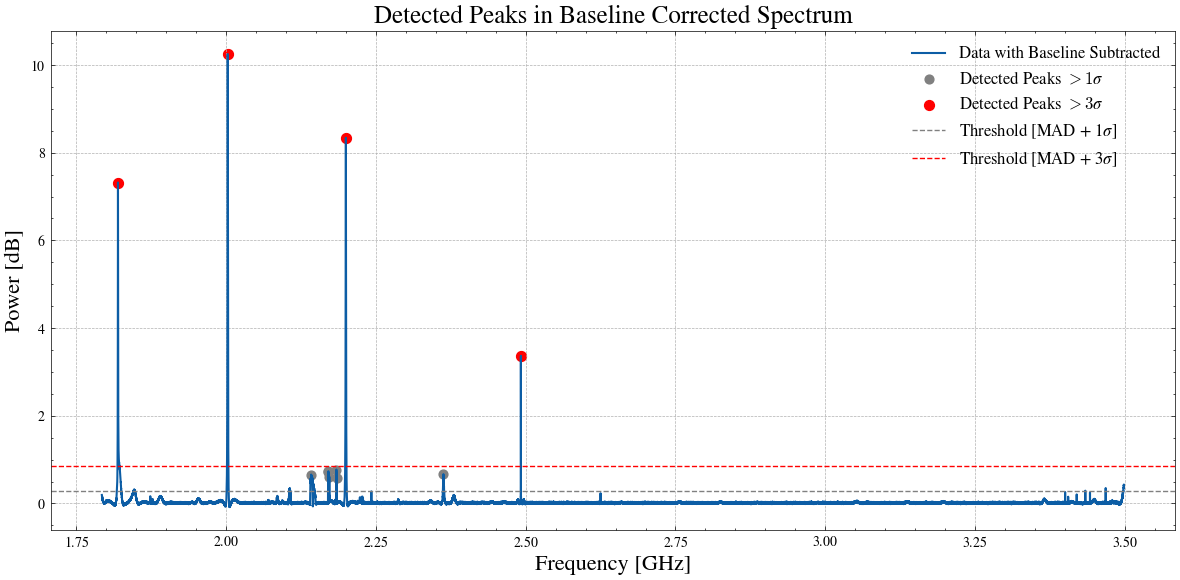

In [5]:


##############################################
#                                            #
#                                            #
#                                            #
#                                            #
##############################################



# Baseline corrected and peaks detection
for g in groups:

    power_base_core = base_correction(freq, spectrum_dB)

        
    # Find peaks above 1 sigma from the MAD
    peaks, propreties = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + np.std(power_base_core),
                                distance=10,
                                prominence=0.5
                                )
    # Find peaks above 3 sigma from the MAD
    peaks1, propreties1 = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + 3*np.std(power_base_core),
                                distance=10,
                                prominence=0.5
                                )

    plt.figure(figsize=(12, 6))

    # --- Plot baseline-corrected spectrum ---
    plt.plot(freq, power_base_core, label=f'Data with Baseline Subtracted', lw=1.5)

    # --- Plot detected peaks ---
    plt.scatter(freq[peaks], power_base_core[peaks], 
                color='gray', s=40, label='Detected Peaks $> 1σ$')

    plt.scatter(freq[peaks1], power_base_core[peaks1], 
                color='red', s=50, label='Detected Peaks $> 3σ$')

    # --- Plot threshold lines ---
    plt.axhline(y=MAD(power_base_core) + np.std(power_base_core), 
                color='gray', linestyle='--', label='Threshold [MAD + 1$σ$]')

    plt.axhline(y=MAD(power_base_core) + 3*np.std(power_base_core), 
            color='red', linestyle='--', label='Threshold [MAD + 3$σ$]')

    # --- Labels and formatting ---
    plt.xlabel("Frequency [GHz]",fontsize=16)
    plt.ylabel("Power [dB]",fontsize=16)
    plt.title("Detected Peaks in Baseline Corrected Spectrum", fontsize=18)
    plt.grid(True, linestyle='--')
    plt.legend(fontsize=12)
    plt.tight_layout()

   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.png', dpi=300)
   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.pdf', dpi=300)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in freq[peaks]]
    formatted_freqs1 = [f"{f:.4f}" for f in freq[peaks1]]

    print(f"Detected peak > 1σ are frequencies (GHz): {formatted_freqs}")
    print(f"Detected peak > 3σ are frequencies (GHz): {formatted_freqs1}")




In [6]:
mask = (freq > 2.00) & (freq < 2.007)


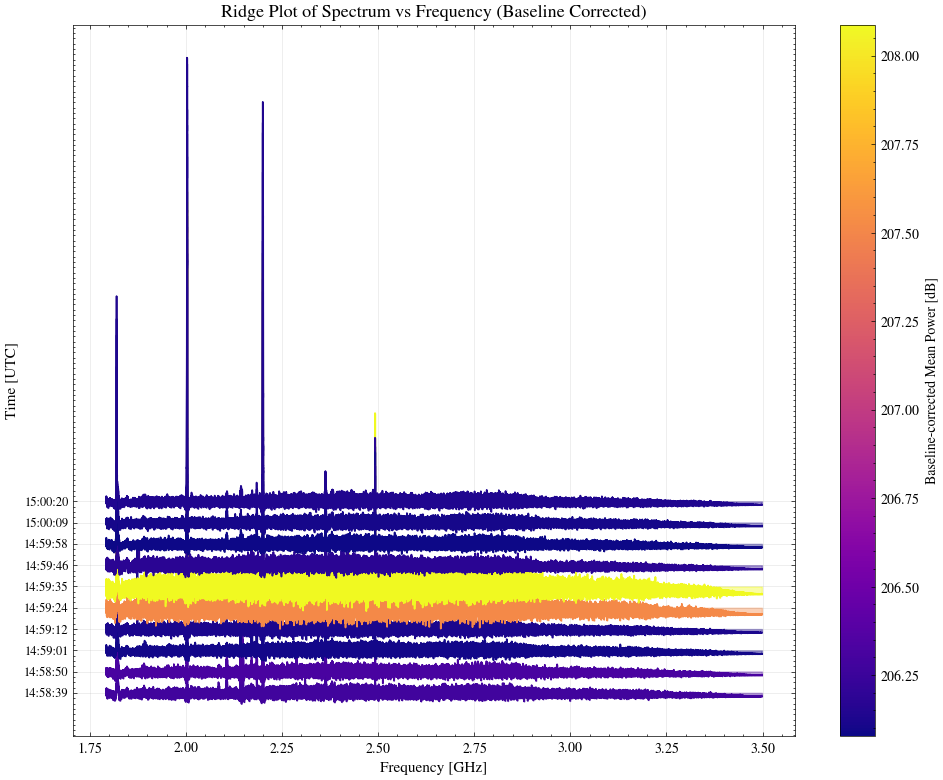

In [7]:

n_time, n_freq = spectrum.shape

# --- Configuration ---
n_samples = 10  # number of ridges to show
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

# --- Compute detrended (baseline-corrected) power for color normalization ---
det_power = []
mean_spectra = []

for k in idx:
    # Average spectrum at selected time
    mean_spectrum = spectrum[k, :]
    
    # --- Apply baseline correction ---
    corrected_spectrum = base_correction(freq, mean_spectrum)
    mean_spectra.append(corrected_spectrum)
    
    # Compute power in dB after correction
    pwr = 10 * np.log10(np.nanmean(corrected_spectrum**2))
    det_power.append(pwr)

# --- Normalize color map according to corrected power ---
norm = plt.Normalize(vmin=np.min(det_power), vmax=np.max(det_power))
colors = cm.plasma(norm(det_power))

 # --- Convert Time to UTC Datetime ---
time_utc = pd.to_datetime(time, unit="s", utc=True)

# --- Create figure ---
fig, ax = plt.subplots(figsize=(10, 8))

for i, (y, color) in enumerate(zip(mean_spectra, colors)):
    # Normalize each corrected spectrum for ridge shape visualization
    y_norm = (y - np.nanmean(y)) / np.nanstd(y)
    
    # Vertical offset per ridge
    offset = i * 2.0
    
    # --- Plot ridge ---
    ax.plot(freq, y_norm + offset, color=color, lw=1.2)
    ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

# --- Colorbar for power interpretation ---
sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Baseline-corrected Mean Power [dB]')

# --- Y-axis: Time labels (UTC) ---
n_ticks = min(10, n_samples)
tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
tick_labels = [time_utc[idx[i]].strftime("%H:%M:%S") for i in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and aesthetics ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_title("Ridge Plot of Spectrum vs Frequency (Baseline Corrected)", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
with h5py.File(filename,'r') as f:
    for g in groups:
        freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
        spectrum = f[f"{g}/spectrum"][30:,1600:-60]    # (time × freq)
        time = f[f"{g}/timestamp"][30:,0]

        # build UTC time array
        time_utc = np.array([datetime.utcfromtimestamp(t) for t in time])

        n_samples = 10  # number of time segments
        n_time, n_freq = spectrum.shape

        # Split time indices into chunks
        time_chunks = np.array_split(np.arange(n_time), n_samples)

        mean_spectra = []
        det_power = []

        for index, chunk in enumerate(time_chunks):

            # average spectrum over the chunk
            #mean_spectrum = 10 * np.log10(np.mean(spectrum[chunk, :]**2, axis=0))
            mean_spectrum = (np.mean(spectrum[chunk, :], axis=0))


            print(mean_spectrum)
        #     # baseline correction
            base_cor_spec = base_correction(freq, mean_spectrum)
            base_cor_spec = 10 * np.log10(base_cor_spec**2)

            print(base_cor_spec)

        #     data_plot = base_cor_spec[mask] 
        #     det_power.append(data_plot)

        # det_power = np.array(det_power)


        break

[1.8709080e+11 1.8831519e+11 1.8705575e+11 ... 4.1166661e+09 4.1145326e+09
 4.1120223e+09]
[195.43404 197.15436 195.5882  ... 167.7617  167.77295 167.77081]
[1.8843438e+11 1.8761169e+11 1.8828732e+11 ... 4.1206356e+09 4.1185267e+09
 4.1049864e+09]


/tmp/ipykernel_1018035/384914130.py:29: RuntimeWarning: divide by zero encountered in log10
  base_cor_spec = 10 * np.log10(base_cor_spec**2)


[196.56464 195.53545 196.55627 ... 167.76514 167.77757 167.37527]
[1.9878901e+11 1.9879295e+11 1.9846577e+11 ... 4.1440397e+09 4.1606799e+09
 4.1365673e+09]
[196.04144 196.14296 195.78833 ... 167.70367 168.36185 167.61261]
[2.7421550e+11 2.7492539e+11 2.7292158e+11 ... 4.4555837e+09 4.4427238e+09
 4.4644224e+09]
[195.70757 196.75287 193.88748 ... 168.44006 168.1     168.89682]
[3.8005273e+11 3.7973741e+11 3.7974216e+11 ... 9.6337459e+09 9.6396268e+09
 9.5844024e+09]
[194.98465 194.59502 194.71373 ... 175.31792 175.49359 174.7444 ]
[3.6031670e+11 3.5905605e+11 3.6022216e+11 ... 7.9819156e+09 7.9783711e+09
 7.9613076e+09]
[194.6272  192.45877 194.70172 ... 173.46698 173.4943  173.27039]
[2.4848274e+11 2.4842733e+11 2.4902548e+11 ... 4.2279301e+09 4.2457357e+09
 4.2341773e+09]
[195.03748 195.0628  196.03397 ... 167.97716 168.65532 168.36115]
[1.9304682e+11 1.9313479e+11 1.9299390e+11 ... 4.1395589e+09 4.1490975e+09
 4.1324339e+09]
[196.13326 196.34529 196.2515  ... 168.01077 168.41586 167

In [9]:
mean_spectrum.shape

(63877,)

In [10]:
from mpl_toolkits.mplot3d import Axes3D


In [11]:
import matplotlib.dates as mdates

time_numeric = mdates.date2num(time_utc)

FREQ, TIME = np.meshgrid(freq, time_numeric)

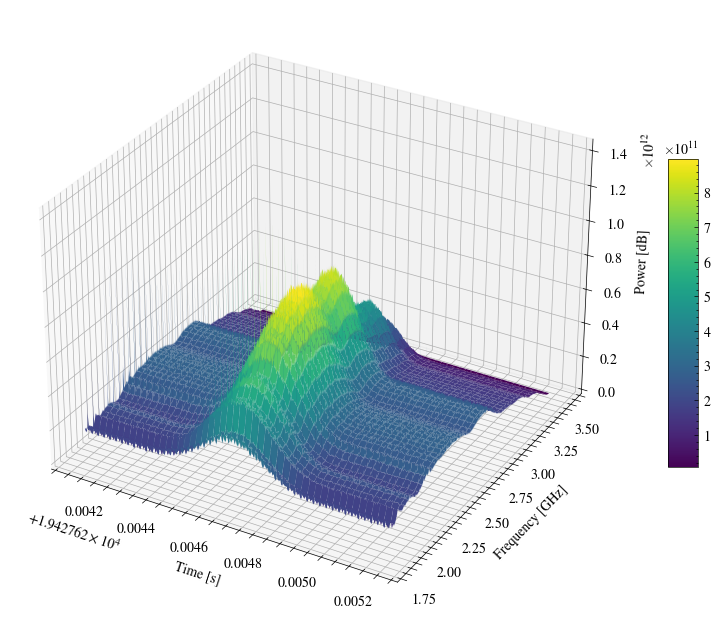

In [12]:

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    TIME,
    FREQ,
    spectrum,
    cmap='viridis',
    edgecolor='none'
)

ax.set_ylabel('Frequency [GHz]')
ax.set_xlabel('Time [s]')
ax.set_zlabel('Power [dB]')

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
plt.show()

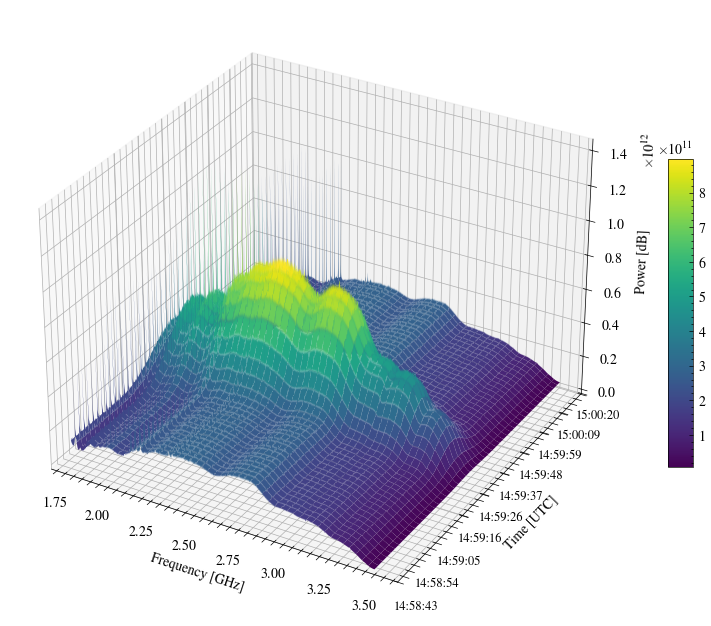

In [13]:

# --- Convert time to numeric seconds ---
time_seconds = np.array(
    [(t - time_utc[0]).total_seconds() for t in time_utc]
)

# --- Meshgrid ---
FREQ, TIME = np.meshgrid(freq, time_seconds)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# --- Surface ---
surf = ax.plot_surface(
    FREQ,
    TIME,
    spectrum,
    cmap='viridis',
    edgecolor='none'
)

# Ensure axis limits are correct
ax.set_ylim(time_seconds.min(), time_seconds.max())

# --- Y-axis: Sampled UTC labels ---
n_samples = len(time_seconds)
n_ticks = min(10, n_samples)

tick_indices = np.linspace(0, n_samples - 1, n_ticks, dtype=int)

tick_positions = time_seconds[tick_indices]
tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_indices]

ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=9)

ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Time [UTC]")
ax.set_zlabel("Power [dB]")

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=12)

plt.show()

[]

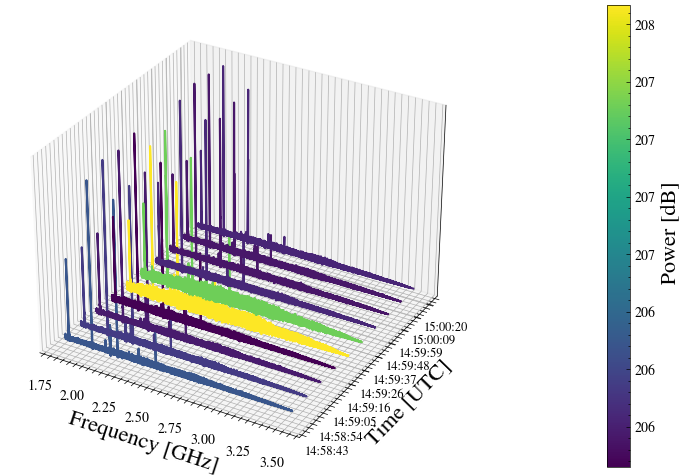

In [14]:


n_time, n_freq = spectrum.shape

# --- Configuration ---
n_samples = 10
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

# --- Convert Time to UTC Datetime ---
time_utc = pd.to_datetime(time, unit="s", utc=True)

# --- Convert time to numeric seconds (for 3D axis) ---
time_seconds = np.array(
    [(t - time_utc[0]).total_seconds() for t in time_utc]
)

# --- Compute detrended power + corrected spectra ---
det_power = []
mean_spectra = []
selected_times = []

for k in idx:
    mean_spectrum = spectrum[k, :]
    
    corrected_spectrum = base_correction(freq, mean_spectrum)
    mean_spectra.append(corrected_spectrum)
    
    pwr = 10 * np.log10(np.nanmean(corrected_spectrum**2))
    det_power.append(pwr)
    
    selected_times.append(time_seconds[k])

# --- det_power: list or array of mean power per ridge ---
det_power = np.array(det_power)

# Compute min/max
vmin = np.min(det_power)
vmax = np.max(det_power)

# Map to 0–1 for colormap
scaled = (det_power - vmin) / (vmax - vmin)

# Get colors from colormap
colors = cm.viridis(scaled)  # This returns RGBA array

# --- Create 3D Figure ---
fig = plt.figure(figsize=(18, 6))
ax = fig.add_subplot(111, projection='3d')

for y_spec, t_sec, color in zip(mean_spectra, selected_times, colors):
    
    # Normalize for shape visualization (same as ridge plot)
    y_norm = (y_spec - np.nanmean(y_spec)) / np.nanstd(y_spec)
    
    # Create time array for this ridge
    time_array = np.full_like(freq, t_sec)
    
    # Plot 3D ridge line
    ax.plot(freq, time_array, y_norm, color=color, lw=1.5)

# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cm.viridis, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.1)
cbar.set_label(" Power [dB]", fontsize=16)
cbar.ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))

# --- Y-axis sampled UTC labels ---
tick_indices = idx
tick_positions = time_seconds[tick_indices]
tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_indices]

ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=9)

# --- Labels ---
ax.set_xlabel("Frequency [GHz]", fontsize=16)
ax.set_ylabel("Time [UTC]", fontsize=16)
ax.set_zticks([])
#ax.set_zlabel("Normalized Power", fontsize=11)

#ax.set_title("3D Ridge Plot of Baseline-Corrected Spectrum", fontsize=13)

#plt.tight_layout()
#plt.show()

#plt.savefig('Plots/Ridge_plot-3d.png', dpi=300)

/tmp/ipykernel_1018035/1741412860.py:65: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


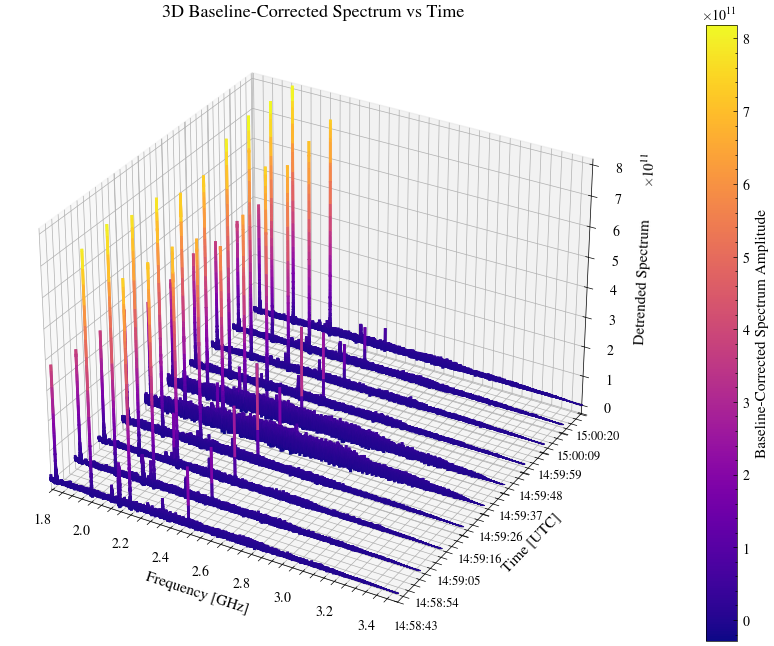

In [15]:

from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection


n_time, n_freq = spectrum.shape
n_samples = 10
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

time_utc = pd.to_datetime(time, unit="s", utc=True)
time_seconds = np.array([(t - time_utc[0]).total_seconds() for t in time_utc])

# Compute baseline-corrected spectra
corrected_spectra = []
selected_times = []

for k in idx:
    mean_spectrum = spectrum[k, :]
    corrected = base_correction(freq, mean_spectrum)
    corrected_spectra.append(corrected)
    selected_times.append(time_seconds[k])

corrected_spectra = np.array(corrected_spectra)

# Color map limits based on actual spectrum
vmin = np.nanmin(corrected_spectra)
vmax = np.nanmax(corrected_spectra)
cmap = cm.plasma

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot each ridge with per-point color
for spec, t_sec in zip(corrected_spectra, selected_times):
    # Create segments for Line3DCollection
    points = np.array([freq, np.full_like(freq, t_sec), spec]).T.reshape(-1,1,3)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    
    lc = Line3DCollection(segments, cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
    lc.set_array(spec)
    lc.set_linewidth(2)
    ax.add_collection(lc)

# Auto-scale axes
ax.set_xlim(freq.min(), freq.max())
ax.set_ylim(time_seconds[idx].min(), time_seconds[idx].max())
ax.set_zlim(vmin, vmax)

# Colorbar
mappable = cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
mappable.set_array([])
cbar = plt.colorbar(mappable, ax=ax, pad=0.1)
cbar.set_label("Baseline-Corrected Spectrum Amplitude", fontsize=11)

# Y-axis: Time labels
tick_positions = time_seconds[idx]
tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in idx]
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=9)

ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_ylabel("Time [UTC]", fontsize=11)
ax.set_zlabel("Detrended Spectrum", fontsize=11)
ax.set_title("3D Baseline-Corrected Spectrum vs Time", fontsize=13)

plt.tight_layout()
plt.show()

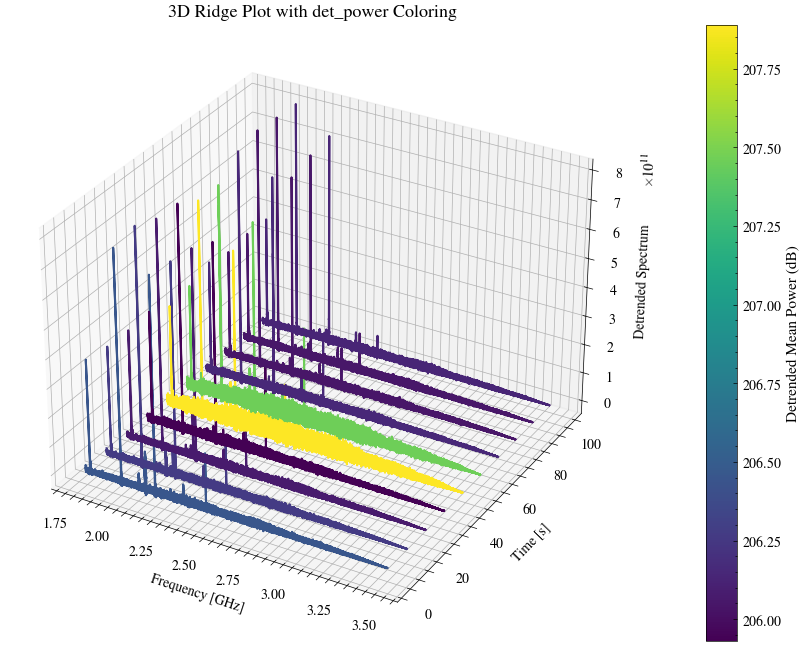

In [16]:

# --- Choose colormap ---
cmap = cm.viridis

# --- Create 3D Figure ---
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

for y_spec, t_sec, pwr in zip(mean_spectra, selected_times, det_power):
    
    # Use original spectrum shape (not normalized)
    y_plot = y_spec  # keep true baseline-corrected values
    
    # Create time array for this ridge
    time_array = np.full_like(freq, t_sec)
    
    # Convert power to color using colormap directly
    # First, scale power to 0–1 relative to global min/max
    vmin = np.min(det_power)
    vmax = np.max(det_power)
    color = cmap((pwr - vmin) / (vmax - vmin))  # value between 0 and 1
    
    # Plot 3D ridge line
    ax.plot(freq, time_array, y_plot, color=color, lw=1.5)

# --- Colorbar ---
mappable = cm.ScalarMappable(cmap=cmap)
mappable.set_clim(vmin, vmax)
cbar = plt.colorbar(mappable, ax=ax, pad=0.1)
cbar.set_label("Detrended Mean Power (dB)", fontsize=11)

# --- Labels ---
ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Time [s]")
ax.set_zlabel("Detrended Spectrum")
ax.set_title("3D Ridge Plot with det_power Coloring", fontsize=13)

plt.show()